<a href="https://colab.research.google.com/github/Edith7542/Customer_churn/blob/main/Customer_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files

uploaded = files.upload()


Saving Customer Churn.csv to Customer Churn.csv


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


In [3]:

df = pd.read_csv("Customer Churn.csv")

df.head()


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (3150, 14)


In [5]:

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Examine customer churn
print("\nChurn Distribution:")
print(df["Churn"].value_counts())


Missing Values:
Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

Duplicate Rows:
300

Churn Distribution:
Churn
0    2655
1     495
Name: count, dtype: int64


In [6]:

# Select customers with high calling frequency
high_call_customers = df[
    df["Frequency of use"] > 100
]

# Display the number of matching records
print("High Call Volume Customers:",
      len(high_call_customers))

# Display selected customer information
display(
    high_call_customers[
        [
            "Frequency of use",
            "Seconds of Use",
            "Subscription  Length",
            "Customer Value",
            "Churn"
        ]
    ].head(10)
)


High Call Volume Customers: 708


,Frequency of use,Seconds of Use,Subscription Length,Customer Value,Churn
7,121,9115,37,945.440,0
8,169,13773,38,557.680,0
12,225,15140,38,830.600,0
14,182,15485,37,1380.015,0
19,127,7508,37,2071.575,0
20,154,11465,37,317.975,0
33,238,16075,31,734.085,0
34,116,6965,34,1538.145,0
45,141,6393,17,676.530,0
46,171,8933,15,410.100,0


In [8]:
# Clean up the column names by removing extra spaces
df.columns = df.columns.str.strip().str.replace(r'\s+', ' ', regex=True)

# sort and display clean column names
sorted_customers = df.sort_values(
    by=["Subscription Length", "Charge Amount"],
    ascending=[False, False]
)

display(
    sorted_customers[
        [
            "Subscription Length",
            "Charge Amount",
            "Customer Value",
            "Churn"
        ]
    ].head(10)
)

,Subscription Length,Charge Amount,Customer Value,Churn
2351,47,0,152.160,0
2362,46,5,941.840,0
2355,46,3,393.520,0
2359,46,3,189.475,0
2363,46,3,1355.075,0
2350,46,2,308.880,0
2353,46,2,392.975,0
2354,46,2,244.440,0
2356,46,2,842.000,0
2358,46,2,668.920,0


In [12]:

average_durations = []

for index, customer in df.iterrows():

    seconds = customer["Seconds of Use"]
    frequency = customer["Frequency of use"]

    if frequency > 0:
        average = seconds / frequency
    else:
        average = 0

    average_durations.append(average)

df["Average Call Duration"] = average_durations

display(
    df[
        [
            "Seconds of Use",
            "Frequency of use",
            "Average Call Duration"
        ]
    ].head(10)
)


,Seconds of Use,Frequency of use,Average Call Duration
0,4370,71,61.549296
1,318,5,63.600000
2,2453,60,40.883333
3,4198,66,63.606061
4,2393,58,41.258621
5,3775,82,46.036585
6,2360,39,60.512821
7,9115,121,75.330579
8,13773,169,81.497041
9,4515,83,54.397590


In [13]:

# Predictor variables
X = df.drop(
    columns=["Churn", "Age Group", "Status"]
)

# Target variable
y = df["Churn"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)


Predictor shape: (3150, 12)
Target shape: (3150,)


In [14]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 2520
Testing records: 630


In [18]:

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed.")


Model training completed.


In [19]:

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Churn": y_test.to_numpy(),
    "Predicted Churn": y_pred
})

display(results.head(10))


,Actual Churn,Predicted Churn
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,1,0
6,0,0
7,0,0
8,0,0
9,0,0


Model Accuracy: 0.9032

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.95       531
           1       0.93      0.41      0.57        99

    accuracy                           0.90       630
   macro avg       0.92      0.70      0.76       630
weighted avg       0.91      0.90      0.89       630



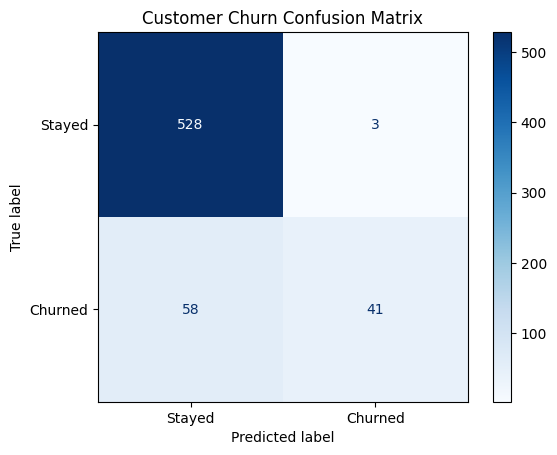

In [21]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
).plot(cmap="Blues")

plt.title("Customer Churn Confusion Matrix")
plt.show()

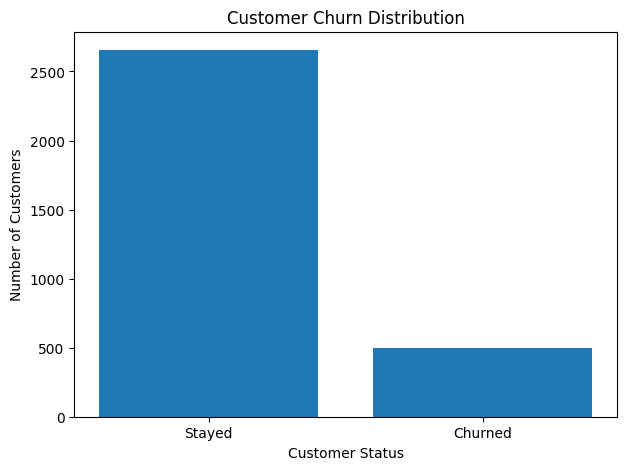

In [22]:

churn_counts = df["Churn"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Stayed", "Churned"],
    churn_counts.values
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.show()
